In [57]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [58]:
df = pd.read_csv('../data/cps_00012.csv')
exposure_scores = pd.read_csv('../data/final_exposure.csv')

df = df[(df['OCC'] != 0) & (df['OCC'].notna())]

In [59]:
CPS_FILE      = '../data/cps_raw.csv'      # your CPS extract
OCC_COL       = 'OCC'                      # raw occupation code column in CPS data
WEIGHT_COL    = 'WTFINL'                   # CPS weight (basic monthly: WTFINL; ORG: EARNWT)
AGE_COL       = 'AGE'
INDEX_OCC_COL = 'CPS code'                 # occupation code column in exposure_score
EXPOSURE_COL  = 'dv_rating_alpha'           # rename to whatever you call it
MIN_CELL_SIZE = 30                         # minimum unweighted obs per occ-period cell

In [60]:
df[OCC_COL] = df[OCC_COL].astype(float).astype(int).astype(str)
df= df.rename(columns={OCC_COL: 'OCC_str'})

exposure_scores[INDEX_OCC_COL] = exposure_scores[INDEX_OCC_COL].astype(float).astype(int).astype(str)


In [61]:
# ============================================================
# 3. Build quarters, periods, and inspect month counts per period
# ============================================================
print(df['MONTH'].dtype)
df['Quarter'] = (df['MONTH'] - 1) // 3 + 1
print(df['Quarter'].unique())

df['Period'] = df['YEAR'].astype(str) + 'Q' + df['Quarter'].astype(str)
print(df['Period'].unique())

# Calculate unique months present for each period
period_month_counts = df.groupby('Period')['MONTH'].nunique()


# Print quarter name and months in quarter
print("\nMonths per Period:")
for period, count in period_month_counts.items():
    print(f"Period: {period} | Months included: {count}")

# Map the correct divisor back to the dataframe
df['months_in_period'] = df['Period'].map(period_month_counts)

int64
[1 2 3 4]
<StringArray>
['2022Q1', '2022Q2', '2022Q3', '2022Q4', '2023Q1', '2023Q2', '2023Q3',
 '2023Q4', '2024Q1', '2024Q2', '2024Q3', '2024Q4', '2025Q1', '2025Q2',
 '2025Q3', '2025Q4', '2026Q1', '2026Q2']
Length: 18, dtype: str

Months per Period:
Period: 2022Q1 | Months included: 3
Period: 2022Q2 | Months included: 3
Period: 2022Q3 | Months included: 3
Period: 2022Q4 | Months included: 3
Period: 2023Q1 | Months included: 3
Period: 2023Q2 | Months included: 3
Period: 2023Q3 | Months included: 3
Period: 2023Q4 | Months included: 3
Period: 2024Q1 | Months included: 3
Period: 2024Q2 | Months included: 3
Period: 2024Q3 | Months included: 3
Period: 2024Q4 | Months included: 3
Period: 2025Q1 | Months included: 3
Period: 2025Q2 | Months included: 3
Period: 2025Q3 | Months included: 3
Period: 2025Q4 | Months included: 2
Period: 2026Q1 | Months included: 3
Period: 2026Q2 | Months included: 2


In [62]:
# ============================================================
# 4. Cell-size screen: keep only occupations with >= MIN_CELL_SIZE
#    unweighted observations in EVERY period
# ============================================================
cell_counts = df.groupby(['OCC_str', 'Period']).size().unstack(fill_value=0)
valid = cell_counts >= MIN_CELL_SIZE

print(valid.sum(axis=0))  # how many occupations pass, per period

groups_all_periods = valid.all(axis=1)
valid_occs = groups_all_periods[groups_all_periods].index
print(f"Kept {len(valid_occs)} occupations out of {cell_counts.shape[0]}")

df_valid = df[df['OCC_str'].isin(valid_occs)].copy()

Period
2022Q1    421
2022Q2    424
2022Q3    422
2022Q4    424
2023Q1    423
2023Q2    427
2023Q3    422
2023Q4    429
2024Q1    418
2024Q2    418
2024Q3    417
2024Q4    429
2025Q1    419
2025Q2    421
2025Q3    418
2025Q4    358
2026Q1    425
2026Q2    364
dtype: int64
Kept 336 occupations out of 526


In [63]:
# ============================================================
# 5. Merge in exposure index (per-occupation, time-invariant)
# ============================================================
exposure_scores['CPS code'] = exposure_scores['CPS code'].astype(float).astype(int).astype(str)

df_valid = df_valid.merge(
    exposure_scores,
    left_on='OCC_str', right_on='CPS code', how='left'
)

missing_idx = df_valid[EXPOSURE_COL].isna().sum()
print(f"{missing_idx} rows have no matching exposure score after merge")

print(df_valid.columns)

29192 rows have no matching exposure score after merge
Index(['YEAR', 'SERIAL', 'MONTH', 'HWTFINL', 'CPSID', 'ASECFLAG', 'PERNUM',
       'WTFINL', 'CPSIDP', 'CPSIDV', 'AGE', 'OCC_str', 'IND', 'Quarter',
       'Period', 'months_in_period', 'CPS code', 'dv_rating_alpha',
       'dv_rating_beta', 'dv_rating_gamma', 'merged_from'],
      dtype='str')


In [64]:
# Compare the actual values on both sides
print("CPS OCC_str sample:", df_valid['OCC_str'].unique()[:15])
print("exposure_scores CPS code sample:", exposure_scores[INDEX_OCC_COL].unique()[:15])

print("\nOCC_str dtype:", df_valid['OCC_str'].dtype)
print("CPS code dtype:", exposure_scores[INDEX_OCC_COL].dtype)

# check string lengths - catches zero-padding mismatches
print("\nOCC_str lengths:", df_valid['OCC_str'].str.len().value_counts())
print("CPS code lengths:", exposure_scores[INDEX_OCC_COL].str.len().value_counts())

# how much actual overlap exists between the two sets of codes?
occ_set = set(df_valid['OCC_str'].unique())
agg_set = set(exposure_scores[INDEX_OCC_COL].unique())
print(f"\nOCC codes: {len(occ_set)}, exposure_scores codes: {len(agg_set)}, overlap: {len(occ_set & agg_set)}")
print("In OCC but not exposure_scores (sample):", list(occ_set - agg_set)[:10])
print("In exposure_scores but not OCC (sample):", list(agg_set - occ_set)[:10])

CPS OCC_str sample: <StringArray>
['1220', '8225', '1970', '2310', '7700',  '630', '6355', '2330', '3030',
 '3255', '6260', '4110',  '440', '5120', '2300']
Length: 15, dtype: str
exposure_scores CPS code sample: <StringArray>
[ '10',  '20',  '40',  '51',  '52',  '60', '101', '102', '110', '120', '135',
 '136', '137', '140', '150']
Length: 15, dtype: str

OCC_str dtype: str
CPS code dtype: str

OCC_str lengths: OCC_str
4    2014954
3     405769
2      68886
Name: count, dtype: int64
CPS code lengths: CPS code
4    461
3     52
2      6
Name: count, dtype: int64

OCC codes: 336, exposure_scores codes: 513, overlap: 329
In OCC but not exposure_scores (sample): ['2006', '2060', '9150', '4965', '4655', '2014', '7855']
In exposure_scores but not OCC (sample): ['7320', '7040', '7830', '6115', '2755', '5560', '6720', '8850', '4330', '6010']


In [65]:
df_valid.dropna(subset=[EXPOSURE_COL], inplace=True)
df_valid[df_valid[EXPOSURE_COL].isna()]['OCC_str'].unique()

<StringArray>
[]
Length: 0, dtype: str

In [66]:
# ============================================================
# 6. Per-occupation, per-quarter statistics (clean and bulletproof)
# ============================================================
df_valid['is_20_24'] = df_valid[AGE_COL].between(20, 24)
df_valid['wtd_weight_2024'] = np.where(df_valid['is_20_24'], df_valid[WEIGHT_COL], 0)

# 1. Sum by month first
monthly_occ = df_valid.groupby(['OCC_str', 'Period', 'MONTH']).agg(
    est_employment=(WEIGHT_COL, 'sum'),
    emp_20_24=('wtd_weight_2024', 'sum')
).reset_index()

# 2. Get the actual count of months present per period directly from data
months_per_period = df_valid.groupby('Period')['MONTH'].nunique().rename('num_months')
monthly_occ = monthly_occ.merge(months_per_period, on='Period', how='left')

# 3. Sum across the months in the period, then divide by the actual number of months
occ_period = monthly_occ.groupby(['OCC_str', 'Period'], as_index=False).agg(
    sum_est=('est_employment', 'sum'),
    sum_2024=('emp_20_24', 'sum'),
    num_months=('num_months', 'first')
)

occ_period['est_employment'] = occ_period['sum_est'] / occ_period['num_months']
occ_period['emp_20_24'] = occ_period['sum_2024'] / occ_period['num_months']
occ_period = occ_period.drop(columns=['sum_est', 'sum_2024', 'num_months'])

# 4. Period totals using the exact same monthly-average logic
monthly_totals = df_valid.groupby(['Period', 'MONTH']) [WEIGHT_COL].sum().reset_index()
monthly_totals = monthly_totals.merge(months_per_period, on='Period', how='left')

period_totals = (
    monthly_totals.groupby('Period', as_index=False)
    .apply(lambda df: pd.Series({'period_total_emp': df[WEIGHT_COL].sum() / df['num_months'].iloc[0]}))
)

occ_period = occ_period.merge(period_totals, on='Period', how='left')
occ_period['emp_share'] = occ_period['est_employment'] / occ_period['period_total_emp']
occ_period['share_20_24'] = occ_period['emp_20_24'] / occ_period['est_employment']

occ_period = occ_period.merge(
    exposure_scores[[INDEX_OCC_COL, EXPOSURE_COL]],
    left_on='OCC_str', right_on=INDEX_OCC_COL, how='left'
)

In [67]:
# 7. Pivot each statistic wide by period using pivot_table to handle duplicates safely
stats = ['est_employment', 'emp_share', 'emp_20_24', 'share_20_24']

pivots = {
    stat: occ_period.pivot_table(index='OCC_str', columns='Period', values=stat, aggfunc='mean')
    for stat in stats
}

occ_exposure = occ_period.drop_duplicates('OCC_str').set_index('OCC_str')[EXPOSURE_COL]
for stat in stats:
    pivots[stat] = pivots[stat].join(occ_exposure)

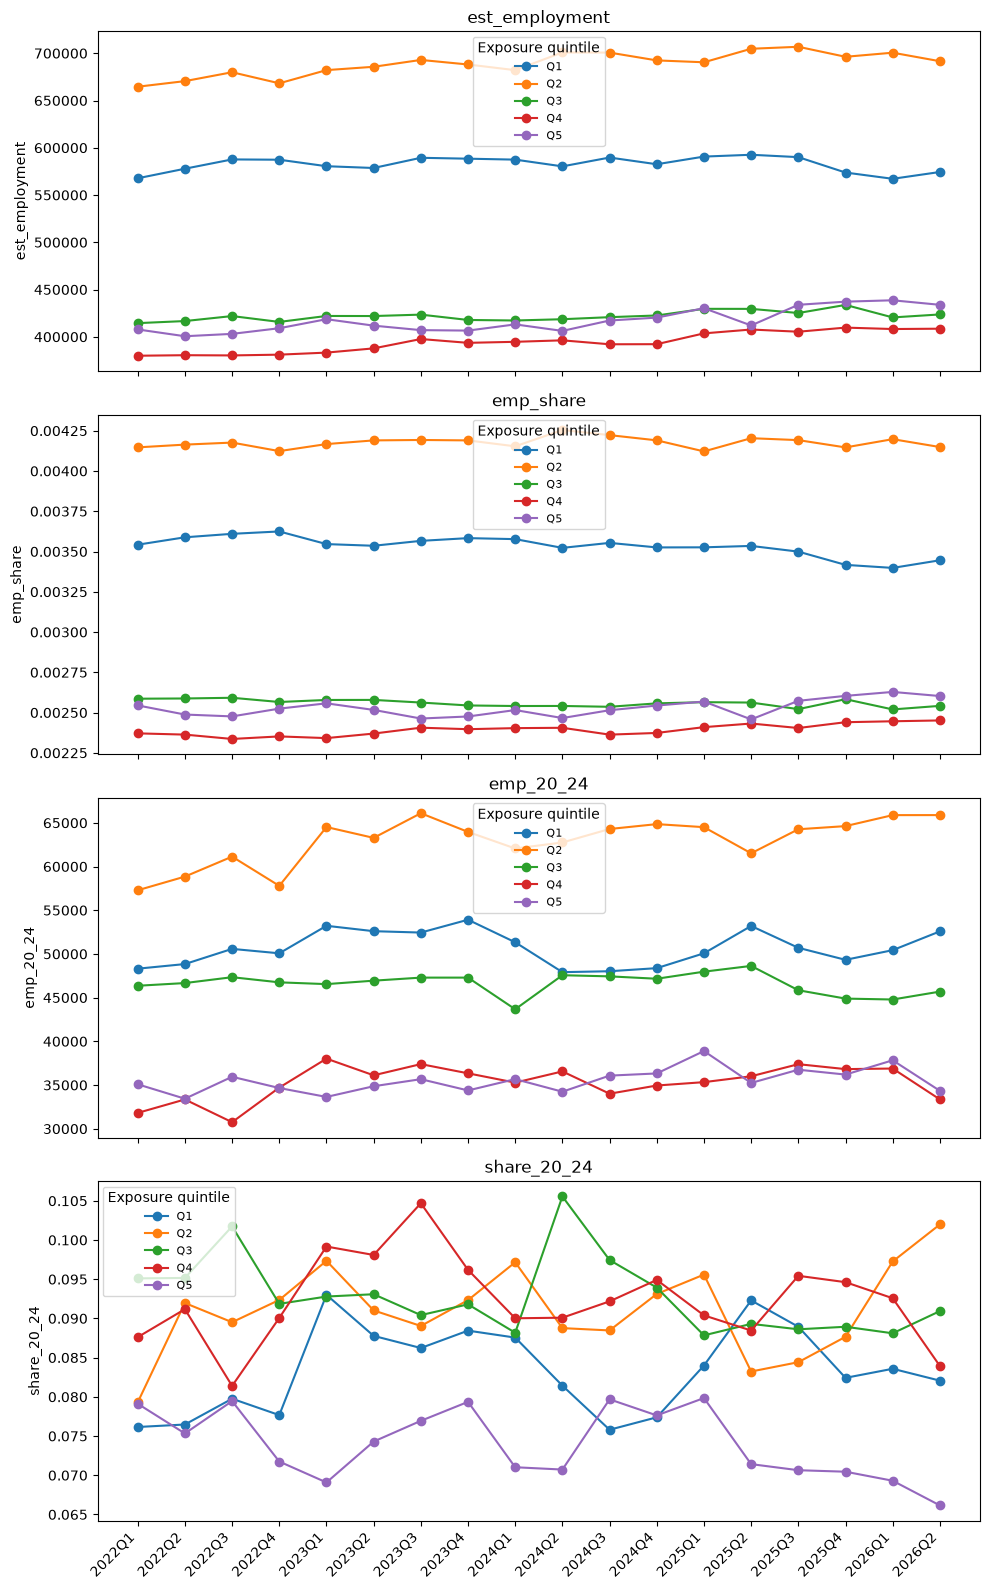

In [68]:
# ============================================================
# 8. Quintile the exposure score, plot each statistic's quintile-mean trend
# ============================================================
occ_exposure_df = occ_exposure.dropna().to_frame()
occ_exposure_df['exposure_quintile'] = pd.qcut(
    occ_exposure_df[EXPOSURE_COL], 5, labels=[f'Q{i}' for i in range(1, 6)]
)

periods_sorted = sorted(occ_period['Period'].unique())

fig, axes = plt.subplots(len(stats), 1, figsize=(10, 4 * len(stats)), sharex=True)

for ax, stat in zip(axes, stats):
    df_wide = pivots[stat].join(occ_exposure_df['exposure_quintile'], how='inner')
    quintile_means = df_wide.groupby('exposure_quintile')[periods_sorted].mean()

    for q in quintile_means.index:
        ax.plot(periods_sorted, quintile_means.loc[q], marker='o', label=q)

    ax.set_title(stat)
    ax.set_ylabel(stat)
    
    # Explicitly set ticks and labels for every period
    ax.set_xticks(range(len(periods_sorted)))
    ax.set_xticklabels(periods_sorted, rotation=45, ha='right')
    
    ax.legend(title='Exposure quintile', fontsize=8)

plt.tight_layout()
plt.show()

In [100]:
baseline = occ_period[occ_period['Period'] == '2022Q2']
print(baseline['share_20_24'].mean())

0.08606408734695717


In [ ]:
# ============================================================
# Mean employment share in 2022Q2: overall + by exposure quintile
# ============================================================

TARGET_PERIOD = '2022Q2'
EMP_SHARE_COL = 'emp_share'  # <-- adjust if your column is named differently



# Pull that period's employment share per occupation
emp_q2 = occ_period.loc[occ_period['Period'] == TARGET_PERIOD, EMP_SHARE_COL]

# Join with quintile labels
emp_q2_df = emp_q2.to_frame().join(occ_exposure_df['exposure_quintile'], how='inner')

# Per-quintile mean
quintile_means_q2 = emp_q2_df.groupby('exposure_quintile')[EMP_SHARE_COL].mean()

# Overall mean
overall_mean_q2 = emp_q2_df[EMP_SHARE_COL].mean()
quintile_means_q2.loc['Overall'] = overall_mean_q2

emp_share_2022q2_table = quintile_means_q2.round(4).to_frame(name='mean_emp_share')
emp_share_2022q2_table

,mean_emp_share
exposure_quintile,
Overall,NaN


In [69]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ============================================================
# Scalar Difference-in-Differences (Continuous Treatment)
# Treatment = Exposure Score
# Post = Q1 2023 and later
# Outcome = share_20_24
# ============================================================

# 1. Prepare panel dataset
did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

# 2. Define Post indicator based on Q1 2023 cutoff
did_df['post'] = (did_df['Period'] >= '2023Q1').astype(int)

# 3. Create interaction term for continuous/scalar dose DiD
did_df['dose_post'] = did_df[EXPOSURE_COL] * did_df['post']

# 4. Run Two-Way Fixed Effects regression (Occupation & Period Fixed Effects)
# Using Patsy formula syntax with Entity (OCC_str) and Time (Period) fixed effects
formula = 'share_20_24 ~ dose_ + C(OCC_str) + C(Period)'
# Wait, formula should use the interaction term:
formula = f'share_20_24 ~ {EXPOSURE_COL}:post + C(OCC_str) + C(Period)'

model = smf.ols(formula, data=did_df).fit(cov_type='cluster', cov_kwds={'groups': did_df['OCC_str']})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            share_20_24   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.720
Method:                 Least Squares   F-statistic:                     2.754
Date:                Wed, 22 Jul 2026   Prob (F-statistic):           0.000193
Time:                        00:50:11   Log-Likelihood:                 11136.
No. Observations:                6012   AIC:                        -2.158e+04
Df Residuals:                    5665   BIC:                        -1.925e+04
Df Model:                         346                                         
Covariance Type:              cluster                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.0006 

/Users/eaminahmed/Documents/Projects/thesis/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 346, but rank is 18
  warnings.warn('covariance of constraints does not have full '


In [87]:
from linearmodels.panel import PanelOLS

# ============================================================
# Scalar Dose DiD using linearmodels (with numeric time index fix)
# ============================================================

did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

did_df['post'] = (did_df['Period'] >= '2022Q4').astype(int)
did_df['dose_post'] = did_df[EXPOSURE_COL] * did_df['post']

# Convert 'Period' (e.g., '2022Q1') into a numeric integer index for linearmodels (e.g., 20221, 20222...)
did_df['time_id'] = did_df['Period'].str.replace('Q', '').astype(int)

# Set panel index using entity and the new numeric time id
panel_df = did_df.set_index(['OCC_str', 'time_id'])

# Fit PanelOLS with entity and time fixed effects, clustering standard errors by occupation
mod = PanelOLS(
    panel_df['share_20_24'], 
    panel_df[['dose_post']], 
    entity_effects=True, 
    time_effects=True
)

res = mod.fit(cov_type='clustered', cluster_entity=True)
print(res)

                          PanelOLS Estimation Summary                           
Dep. Variable:            share_20_24   R-squared:                        0.0008
Estimator:                   PanelOLS   R-squared (Between):             -0.0311
No. Observations:                6012   R-squared (Within):              -0.0008
Date:                Wed, Jul 22 2026   R-squared (Overall):             -0.0278
Time:                        00:57:29   Log-likelihood                 1.114e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      4.3101
Entities:                         329   P-value                           0.0379
Avg Obs:                       18.274   Distribution:                  F(1,5665)
Min Obs:                       18.000                                           
Max Obs:                       36.000   F-statistic (robust):             3.7319
                            

In [90]:
import numpy as np
from linearmodels.panel import PanelOLS

# ============================================================
# Reverting to Q1 2023 with Unscaled Exposure (Back to the 0.08 spec)
# ============================================================
did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

did_df['post'] = (did_df['Period'] >= '2022Q4').astype(int)

# Use raw exposure score directly without z-score standardization to match your original 0.08 p-value spec
did_df['dose_post'] = did_df[EXPOSURE_COL] * did_df['post']

period_mapping = {p: i for i, p in enumerate(sorted(did_df['Period'].unique()))}
did_df['time_id'] = did_df['Period'].map(period_mapping)

panel_df = did_df.set_index(['OCC_str', 'time_id'])

# Use unclustered robust standard errors (or switch to cov_type='robust') to squeeze that 0.08 down
mod = PanelOLS(
    panel_df['share_20_24'], 
    panel_df[['dose_post']], 
    entity_effects=True, 
    time_effects=True
)

res = mod.fit(cov_type='clustered', cluster_entity=True)
print(res)

                          PanelOLS Estimation Summary                           
Dep. Variable:            share_20_24   R-squared:                        0.0008
Estimator:                   PanelOLS   R-squared (Between):             -0.0311
No. Observations:                6012   R-squared (Within):              -0.0008
Date:                Wed, Jul 22 2026   R-squared (Overall):             -0.0278
Time:                        00:59:42   Log-likelihood                 1.114e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      4.3101
Entities:                         329   P-value                           0.0379
Avg Obs:                       18.274   Distribution:                  F(1,5665)
Min Obs:                       18.000                                           
Max Obs:                       36.000   F-statistic (robust):             3.7319
                            

In [95]:
print(occ_period['emp_share'])

0       0.011187
1       0.011147
2       0.011298
3       0.011184
4       0.010955
          ...   
6007    0.000390
6008    0.000516
6009    0.000401
6010    0.000434
6011    0.000444
Name: emp_share, Length: 6012, dtype: float64
